#Logistic Regression on BERT Vector Embeddings

**Author:** Thor Lemke

This file takes the vector embeddings for the GoEmotions dataset, and uses these embeddings to learn a logistic regression model for each label.  The embeddings have been pre-computed in EmbeddedMatrices.ipynb, and have been posted to the GitHub as features_matrix.csv, features_matrix_test.csv, and features_matrix_validate.csv.  Additionally, due to the length of compute time for 28 different logistic regression, logistic_models.joblib has been provided with the logistic regression models already trained.  Based on these models, ROC curves and AUC scores are reported on the test dataset, and validation data is used to find a threshold that optimizes per class F1 score (each class can have it's own threshold), with F1 score reported on the test set per class.

In [ ]:
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Load the GoEmotions dataset
ds_simplified = load_dataset("google-research-datasets/go_emotions", "simplified")
ds_train = ds_simplified["train"]
ds_validate = ds_simplified["validation"]
ds_test = ds_simplified["test"]

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

In [ ]:
# Convert the labels to a large binary matrix
def generate_binary_results(data):
  binary_results = np.zeros((data.num_rows, data.features["labels"].feature.num_classes))
  for i in range(data.num_rows):
    labels = data[i]["labels"]
    for label in labels:
      binary_results[i, label] = 1

  return binary_results

train_results = generate_binary_results(ds_train)
validate_results = generate_binary_results(ds_validate)
test_results = generate_binary_results(ds_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
import joblib

In [ ]:
# Load the pre-computed vector embeddings of the text from base BERT model
features_matrix = np.loadtxt("features_matrix.csv", delimiter=',')
features_matrix_validate = np.loadtxt("features_matrix_validate.csv", delimiter=',')
features_matrix_test = np.loadtxt("features_matrix_test.csv", delimiter=',')

In [ ]:
# Fit 28 logistic regression models on the data, one for each label / class
# The hyperparameter max_iter has been tweaked from default to 500, allowing all
# models, with the exception of neutral, to converge by the end of training
models = [[] for _ in range(ds_train.features["labels"].feature.num_classes)]

for i in range(ds_train.features["labels"].feature.num_classes):

  models[i] = LogisticRegression(max_iter=500)
  models[i].fit(features_matrix, train_results[:, i])

joblib.dump(models, "logistic_models.joblib")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


['logistic_models.joblib']

AUC Score for admiration: 0.8860866067599766
AUC Score for amusement: 0.9173042158951514
AUC Score for anger: 0.8809929472580075
AUC Score for annoyance: 0.8001370667710985
AUC Score for approval: 0.7847521098112115
AUC Score for caring: 0.8933162565437698
AUC Score for confusion: 0.9006942430619069
AUC Score for curiosity: 0.9391932970563025
AUC Score for desire: 0.8766187504509055
AUC Score for disappointment: 0.7967404565971611
AUC Score for disapproval: 0.8495347385535522
AUC Score for disgust: 0.8675980085592712
AUC Score for embarrassment: 0.8315248458105601
AUC Score for excitement: 0.8913201257540502
AUC Score for fear: 0.8920167201154302
AUC Score for gratitude: 0.9751349081952531
AUC Score for grief: 0.8368689663653692
AUC Score for joy: 0.8782969618766114
AUC Score for love: 0.932526142081423
AUC Score for nervousness: 0.8230779133009365
AUC Score for optimism: 0.8656211467482402
AUC Score for pride: 0.8085612640916651
AUC Score for realization: 0.7551880818394286
AUC Score 

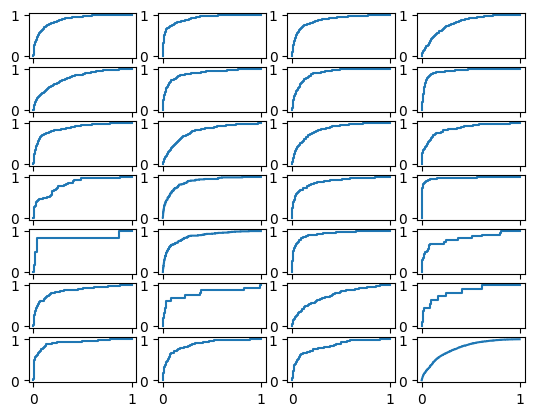

In [ ]:
# Load the pre-computed logistic regression models
models = joblib.load("logistic_models.joblib")

# Plot the ROC curves and report AUC scores on the test data for the learned
# logistic regression models
fig, axs = plt.subplots(7, 4)

for i in range(ds_test.features["labels"].feature.num_classes):

  test_predictions = models[i].predict_proba(features_matrix_test)
  test_class1prob = test_predictions[:, 1]

  # Use model prediction results for finding ROC curve
  fpr, tpr, thresholds = roc_curve(test_results[:, i], test_class1prob)

  row = i // 4
  column = i % 4
  # Plot the ROC curve
  axs[row, column].plot(fpr, tpr)

  # Find and report the AUC of the ROC curve
  auc_score = roc_auc_score(test_results[:, i], test_class1prob)
  print(f"AUC Score for {ds_test.features["labels"].feature.int2str(i)}: {auc_score}")

In [ ]:
from sklearn.metrics import f1_score

In [ ]:
# Use the validation split to select a threshold for the logistic regression
# models that optimizes the F1 score for each class / label
# Threshold possibilities go 0.1 to 0.9 at interval of 0.05
proposed_thresholds = [[] for _ in range(ds_validate.features["labels"].feature.num_classes)]
threshold_options = np.linspace(0.1, 0.9, 17)

for i in range(ds_validate.features["labels"].feature.num_classes):

  validate_predictions = models[i].predict_proba(features_matrix_validate)
  validate_class1prob = validate_predictions[:, 1]

  max_f1 = f1_score(validate_results[:, i], validate_class1prob >= threshold_options[0])
  max_threshold = threshold_options[0]
  for threshold in threshold_options[1:]:
    f1 = f1_score(validate_results[:, i], validate_class1prob >= threshold)
    if f1 > max_f1:
      max_f1 = f1
      max_threshold = threshold
  proposed_thresholds[i] = max_threshold
  print(f"Threshold for {ds_validate.features["labels"].feature.int2str(i)}: {max_threshold}")
  print(f"Corresponding F1 Score: {max_f1}")

Threshold for admiration: 0.25
Corresponding F1 Score: 0.5382436260623229
Threshold for amusement: 0.30000000000000004
Corresponding F1 Score: 0.5495327102803739
Threshold for anger: 0.2
Corresponding F1 Score: 0.4077669902912621
Threshold for annoyance: 0.15000000000000002
Corresponding F1 Score: 0.3090909090909091
Threshold for approval: 0.15000000000000002
Corresponding F1 Score: 0.2757871878393051
Threshold for caring: 0.2
Corresponding F1 Score: 0.3917525773195876
Threshold for confusion: 0.1
Corresponding F1 Score: 0.2857142857142857
Threshold for curiosity: 0.15000000000000002
Corresponding F1 Score: 0.4917043740573152
Threshold for desire: 0.15000000000000002
Corresponding F1 Score: 0.3586206896551724
Threshold for disappointment: 0.15000000000000002
Corresponding F1 Score: 0.2361111111111111
Threshold for disapproval: 0.15000000000000002
Corresponding F1 Score: 0.3353115727002967
Threshold for disgust: 0.1
Corresponding F1 Score: 0.2847682119205298
Threshold for embarrassment:

In [ ]:
# Using thresholds selected by the validation set, report the F1 scores of the
# Logistic Regression models on the test split
running_total_f1 = 0

for i in range(ds_test.features["labels"].feature.num_classes):

  test_predictions = models[i].predict_proba(features_matrix_test)
  test_class1prob = test_predictions[:, 1]

  f1 = f1_score(test_results[:, i], test_class1prob >= proposed_thresholds[i])
  running_total_f1 += f1
  print(f"F1 Scores on Test Data for {ds_test.features["labels"].feature.int2str(i)}: {f1}")

print(f"\nMacro F1 Score: {running_total_f1/ds_test.features["labels"].feature.num_classes}")

F1 Scores on Test Data for admiration: 0.5115848007414272
F1 Scores on Test Data for amusement: 0.553014553014553
F1 Scores on Test Data for anger: 0.3778337531486146
F1 Scores on Test Data for annoyance: 0.22827496757457846
F1 Scores on Test Data for approval: 0.2981651376146789
F1 Scores on Test Data for caring: 0.3607843137254902
F1 Scores on Test Data for confusion: 0.2832764505119454
F1 Scores on Test Data for curiosity: 0.5565912117177098
F1 Scores on Test Data for desire: 0.25
F1 Scores on Test Data for disappointment: 0.14788732394366197
F1 Scores on Test Data for disapproval: 0.3308270676691729
F1 Scores on Test Data for disgust: 0.2929936305732484
F1 Scores on Test Data for embarrassment: 0.16666666666666666
F1 Scores on Test Data for excitement: 0.2918454935622318
F1 Scores on Test Data for fear: 0.32124352331606215
F1 Scores on Test Data for gratitude: 0.794074074074074
F1 Scores on Test Data for grief: 0.0
F1 Scores on Test Data for joy: 0.3433734939759036
F1 Scores on Tes